# Caso 1 · Sistema de pedidos a fábrica — Ventana de octubre de 2026

Calcula cuántas unidades de cada modelo pedir en la ventana que cierra el 30-oct-2026. Parte de la base limpia de [`00_limpieza`](00_limpieza.ipynb) y de las conclusiones de [`01_eda`](01_eda.ipynb). Para el próximo ciclo: actualizar el Excel y las fechas en `00_limpieza` y volver a correr ambos notebooks.

**Secciones:** 1. Supuestos · 2. Calendario · 3. Demanda ajustada · 4. Estacionalidad · 5. Posición al llegar · 6. Stock de seguridad · 7. Pedido · 8. Mezcla por versión · 9. Sensibilidad · 10. Resumen visual · 11. Exportar · 12. Sistema de pedidos (flujo, datos, IA, medición) · 13. Respuesta a la gerencia comercial

## 1. Supuestos
Decisiones que condicionan los resultados de este notebook y por qué se tomaron. En el texto y en el código se citan por su código.

| Código | Supuesto | Por qué | Dónde se aplica |
|---|---|---|---|
| **S1.7** | **Demanda ajustada** = venta neta de 12 meses (`DEMAND_WINDOW_MONTHS`) + leads perdidos por disponibilidad y sustituciones, **solo en los meses de quiebre** (el modelo empezó o terminó el mes en cero). | En los meses sin stock la venta registrada no mide la demanda: está censurada. Las pérdidas con el modelo en stock son de versión o color, así que corrigen la mezcla del pedido, no el volumen. | §3 |
| **S1.8** | El pedido llega con el lead time real (mediana 104 días) y un 12 % de las unidades llega ~1 mes tarde (`LEAD_TIME_DAYS`, `LATE_SHARE`, `LATE_DELAY_MONTHS`). El tránsito que llega antes del pedido suma a la posición, que se trunca en 0. | El lead time observado es estable en todos los trimestres y el "4 meses" del comunicado es conservador; la llegada tardía se repite cada trimestre y la ETA no la anticipa. La posición no puede ser negativa porque la venta perdida en el hueco no se recupera después. | §2, §5 |
| **S1.9** | Nivel de servicio por modelo = margen / (margen + costo de sobrar), con sobrar = 3 meses más de plan piso (`LEFTOVER_EXTRA_MONTHS`) + descuento del 4 % (`LEFTOVER_DISCOUNT`), más una reserva por llegada tardía. La variabilidad se mide con la desviación mensual de la demanda ajustada (que incluye la estacionalidad) sobre el horizonte (√3 meses), no sobre hueco + horizonte. El pedido se redondea a 0 o ≥ mínimo, en múltiplos del lote. | Faltar cuesta el margen de la venta perdida y sobrar cuesta plan piso y descuento: ese cociente (ratio crítico) es el nivel de servicio que minimiza el costo esperado. Los dos atajos de la variabilidad sesgan en sentidos opuestos y se compensan en buena parte (§9). El redondeo es la regla de fábrica. | §6, §7, §9 |
| **S1.10** | **RAV4:** horizonte hasta mayo de 2027, sin stock de seguridad (z = 0), redondeo hacia abajo y descuento de liquidación del 10 % (`END_OF_LIFE`). | Octubre de 2026 es su última ventana, fábrica no apoya la liquidación y la nueva generación (solo híbrida) llega en mayo: lo que sobre se venderá con descuento. El 10 % lleva su ratio crítico por debajo del 50 %, lo que justifica no llevar seguridad; se fija z = 0 en lugar del z negativo que daría el ratio, que con el redondeo hacia abajo quitaría un lote más. | §6, §7 |

In [1]:
from dataclasses import dataclass
from pathlib import Path
from statistics import NormalDist
from types import SimpleNamespace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

ROOT = Path.cwd().resolve().parents[1]  # el notebook corre desde notebooks/caso1/
PROCESSED = ROOT / "data" / "processed" / "caso1_limpio.pkl"
OUTPUTS = ROOT / "outputs"
assert PROCESSED.is_file(), f"No existe {PROCESSED}: ejecuta primero 00_limpieza.ipynb"
d = SimpleNamespace(**pd.read_pickle(PROCESSED))  # base limpia escrita por 00_limpieza.ipynb
MODELOS = d.models
CUTOFF_DATE = d.params["cutoff_date"]
ORDER_WINDOW_CLOSE = d.params["order_window_close"]

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update(
    {
        "figure.figsize": (11, 4.5),
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titlesize": 12,
        "legend.fontsize": 9,
    }
)

# Parámetros del sistema (supuestos S1.7–S1.10, ver §1). Lead time y fracción tardía se recalibran en cada ciclo
# desde la hoja Pedidos, como en 01_eda §7.1; para fijarlos a mano basta sobrescribir las dos constantes.
LATE_THRESHOLD_DAYS = 130  # una unidad es "tardía" si tarda más que esto en llegar
_rec = d.orders[d.orders["Estado"] == "Recibido"]
_lead = (_rec["Fecha de recepción"] - _rec["Fecha pedido"]).dt.days
LEAD_TIME_DAYS = int(_lead.median())  # mediana histórica pedido → patio
LATE_SHARE = float(_rec.loc[_lead > LATE_THRESHOLD_DAYS, "Unidades"].sum() / _rec["Unidades"].sum())
LATE_DELAY_MONTHS = 1.0  # las unidades tardías llegan ~1 mes después
print(f"Lead time mediano: {LEAD_TIME_DAYS} días; unidades que llegan tarde: {LATE_SHARE:.1%}")
DEMAND_WINDOW_MONTHS = 12  # meses de historia para estimar la demanda
LEFTOVER_EXTRA_MONTHS = 3  # meses extra en patio de una unidad que sobra al final del horizonte
LEFTOVER_DISCOUNT = 0.04  # descuento al que llega esa unidad (> 180 días)
END_OF_LIFE = {"RAV4": 0.10}  # modelos en su última ventana → descuento de liquidación (S1.10 · ver §1)
DAYS_PER_MONTH = 365.25 / 12
MESES_ES = {
    1: "ene",
    2: "feb",
    3: "mar",
    4: "abr",
    5: "may",
    6: "jun",
    7: "jul",
    8: "ago",
    9: "sep",
    10: "oct",
    11: "nov",
    12: "dic",
}

Lead time mediano: 104 días; unidades que llegan tarde: 11.9%


## 2. Calendario del ciclo
El lead time real fija el *hueco* (del corte a la llegada del pedido, lo cubren stock y tránsito) y el *horizonte* (de esta llegada a la siguiente, lo cubre el pedido).

*Supuesto S1.8 (ver §1).*

In [2]:
@dataclass(frozen=True)
class CycleDates:
    cutoff: pd.Timestamp
    window_close: pd.Timestamp
    arrival: pd.Timestamp
    next_window_close: pd.Timestamp
    next_arrival: pd.Timestamp

    @property
    def gap_months(self) -> float:
        return (self.arrival - self.cutoff).days / DAYS_PER_MONTH

    @property
    def horizon_months(self) -> float:
        return (self.next_arrival - self.arrival).days / DAYS_PER_MONTH

    def as_frame(self) -> pd.DataFrame:
        filas = {
            "Fecha de corte de los datos": f"{self.cutoff:%d-%b-%Y}",
            "Cierre de la ventana de pedido": f"{self.window_close:%d-%b-%Y}",
            "Llegada estimada del pedido": f"{self.arrival:%d-%b-%Y} (lead time {(self.arrival - self.window_close).days} días)",
            "Cierre de la ventana siguiente": f"{self.next_window_close:%d-%b-%Y}",
            "Llegada del pedido siguiente": f"{self.next_arrival:%d-%b-%Y}",
            "Hueco que cubre stock + tránsito": f"{self.gap_months:.1f} meses",
            "Horizonte que cubre el pedido": f"{self.horizon_months:.1f} meses",
        }
        return pd.DataFrame({"Valor": filas})


def last_business_day(ts: pd.Timestamp) -> pd.Timestamp:
    month = ts.to_period("M")
    return pd.bdate_range(month.start_time, month.end_time)[-1]


def cycle_dates(
    cutoff=CUTOFF_DATE, window_close=ORDER_WINDOW_CLOSE, lead_time_days=LEAD_TIME_DAYS
) -> CycleDates:
    lead = pd.Timedelta(days=lead_time_days)
    next_close = last_business_day(
        window_close + pd.DateOffset(months=3)
    )  # ventanas trimestrales, último día hábil
    return CycleDates(cutoff, window_close, window_close + lead, next_close, next_close + lead)


fechas = cycle_dates()
fechas.as_frame()

,Valor
Fecha de corte de los datos,30-Sep-2026
Cierre de la ventana de pedido,30-Oct-2026
Llegada estimada del pedido,11-Feb-2027 (lead time 104 días)
Cierre de la ventana siguiente,29-Jan-2027
Llegada del pedido siguiente,13-May-2027
Hueco que cubre stock + tránsito,4.4 meses
Horizonte que cubre el pedido,3.0 meses


El pedido llega el **11-feb-2027** y el siguiente el **13-may-2027**: hueco de **4.4 meses** y horizonte de **3.0 meses**. Con el lead time de 4 meses del comunicado (122 días) el hueco crece 18 días y el pedido sube a 394 unidades (+53), sobre todo Hilux (+18) y Yaris (0 → 16) (§9); se usa el lead time observado, estable en los 12 trimestres.

## 3. Demanda ajustada por modelo
La venta subestima la demanda de los modelos que quebraron. Se suman, solo en sus meses de quiebre, los leads perdidos por disponibilidad y las ventas que se fueron a otro modelo (que se restan del modelo que las recibió). Las pérdidas con stock se usan en la mezcla (§8).

*Supuesto S1.7 (ver §1).*

,Venta 12m,Meses en quiebre,Perdidas recuperables,Sustitución neta,Demanda ajustada 12m,Demanda mensual,Desv. mensual,Demanda mensual (solo meses con stock)
Hilux,414,0,0,+0,414,34.5,11.0,34.5
Fortuner,105,2,4,-2,107,8.9,3.1,9.1
Corolla,101,0,0,-3,98,8.2,2.6,8.4
Corolla Cross,213,6,64,+31,308,25.7,9.4,26.8
Yaris,169,0,0,-4,165,13.8,3.6,14.1
Yaris Cross,155,8,39,+8,202,16.8,5.8,20.8
RAV4,113,2,1,-28,86,7.2,3.8,9.0
Land Cruiser Prado,41,0,0,+0,41,3.4,2.0,3.4
Rush,88,6,27,+14,129,10.8,3.8,11.3
Hiace,74,0,0,+0,74,6.2,4.4,6.2


Ajuste de la demanda frente a la venta: {'Corolla': '-3%', 'Corolla Cross': '+45%', 'Yaris': '-2%', 'Yaris Cross': '+30%', 'RAV4': '-24%', 'Rush': '+47%', 'Raize': '-15%'}


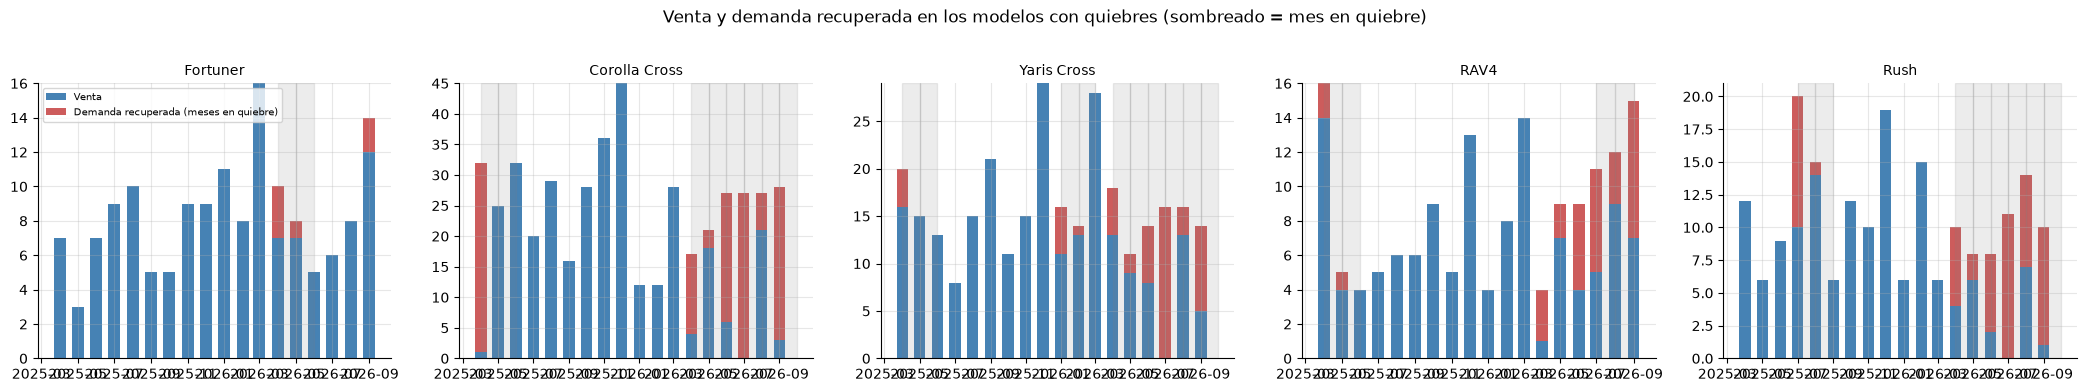

In [3]:
def monthly_table(df, model_col, value_col, months=None) -> pd.DataFrame:
    # Pivote mes × modelo con ceros donde no hay registro
    t = df.pivot_table(index="month", columns=model_col, values=value_col, aggfunc="sum", fill_value=0)
    t = t.reindex(columns=MODELOS, fill_value=0)
    if months is None:
        months = pd.period_range(t.index.min(), t.index.max(), freq="M")
    return t.reindex(months, fill_value=0)


def demand_history(d, cutoff=CUTOFF_DATE) -> SimpleNamespace:
    # Series mensuales por modelo: venta, stock, censura y demanda ajustada
    stock = monthly_table(d.inventory, "Modelo", "Unidades")
    months = stock.loc[: str(cutoff.to_period("M"))].index
    stock = stock.reindex(months, fill_value=0)
    sales = monthly_table(d.base_sales, "Modelo", "Unidades", months)
    stock_start = stock.shift(1).fillna(stock.iloc[0])
    censored = (stock_start == 0) | (stock == 0)

    leads = d.leads[~d.leads["special_fleet"]]
    lost = monthly_table(leads[leads["no_availability"]], "Modelo de interés", "Unidades", months)
    lost_in_stockout = lost.where(censored, 0)

    won_other = leads[(leads["Resultado"] == "Ganada") & leads["Modelo comprado (si difiere)"].notna()]
    subs_in = pd.DataFrame(0.0, index=months, columns=MODELOS)
    subs_out = subs_in.copy()
    pairs = {}  # (modelo de interés, modelo comprado) → unidades sustituidas en meses de quiebre del modelo de interés
    for _, row in won_other.iterrows():
        m, wanted, bought = row["month"], row["Modelo de interés"], row["Modelo comprado (si difiere)"]
        if m in censored.index and wanted in MODELOS and bought in MODELOS and censored.at[m, wanted]:
            subs_in.at[m, wanted] += row["Unidades"]
            subs_out.at[m, bought] += row["Unidades"]
            pairs[(wanted, bought)] = pairs.get((wanted, bought), 0) + row["Unidades"]

    adjusted = sales + lost_in_stockout + subs_in - subs_out
    return SimpleNamespace(
        months=months,
        sales=sales,
        stock=stock,
        censored=censored,
        lost=lost,
        lost_in_stockout=lost_in_stockout,
        subs_in=subs_in,
        subs_out=subs_out,
        pairs=pd.Series(pairs, dtype=float),
        adjusted=adjusted,
    )


def demand_table(hist, window=DEMAND_WINDOW_MONTHS) -> pd.DataFrame:
    last, sales, censored = (
        hist.adjusted.iloc[-window:],
        hist.sales.iloc[-window:],
        hist.censored.iloc[-window:],
    )
    return pd.DataFrame(
        {
            "Venta 12m": sales.sum(),
            "Meses en quiebre": censored.sum(),
            "Perdidas recuperables": hist.lost_in_stockout.iloc[-window:].sum(),
            "Sustitución neta": (hist.subs_in - hist.subs_out).iloc[-window:].sum(),
            "Demanda ajustada 12m": last.sum(),
            "Demanda mensual": last.mean(),
            "Desv. mensual": last.std(ddof=1),
            "Demanda mensual (solo meses con stock)": sales.where(~censored).mean().fillna(last.mean()),
        }
    )


hist = demand_history(d)
demanda = demand_table(hist)
fmt_dem = {c: "{:,.0f}" for c in demanda.columns} | {
    "Demanda mensual": "{:.1f}",
    "Desv. mensual": "{:.1f}",
    "Demanda mensual (solo meses con stock)": "{:.1f}",
    "Sustitución neta": "{:+.0f}",
}
display(
    demanda.style.format(fmt_dem).background_gradient(
        subset=["Meses en quiebre"], cmap="Reds", vmin=0, vmax=12
    )
)
ajuste = demanda["Demanda ajustada 12m"] / demanda["Venta 12m"] - 1
print(
    "Ajuste de la demanda frente a la venta:", {m: f"{v:+.0%}" for m, v in ajuste.items() if abs(v) >= 0.02}
)

con_quiebre = demanda.index[demanda["Meses en quiebre"] > 0]
fig, axes = plt.subplots(1, len(con_quiebre), figsize=(4.2 * len(con_quiebre), 3.8))
ult = slice(str(hist.months[-18]), str(hist.months[-1]))
for ax, m in zip(np.atleast_1d(axes), con_quiebre, strict=False):
    x = hist.sales.loc[ult].index.to_timestamp()
    ax.bar(x, hist.sales.loc[ult, m], width=20, label="Venta", color="steelblue")
    ax.bar(
        x,
        (hist.adjusted - hist.sales).loc[ult, m],
        bottom=hist.sales.loc[ult, m],
        width=20,
        label="Demanda recuperada (meses en quiebre)",
        color="indianred",
    )
    for mes in hist.censored.loc[ult].index[hist.censored.loc[ult, m]]:
        ax.axvspan(mes.start_time, mes.end_time, color="gray", alpha=0.15)
    ax.set_title(m, fontsize=10)
np.atleast_1d(axes)[0].legend(fontsize=7)
fig.suptitle("Venta y demanda recuperada en los modelos con quiebres (sombreado = mes en quiebre)", y=1.02)
plt.tight_layout()
plt.show()

- **Corolla Cross** pasa de 213 a ~310 unidades al año, **Yaris Cross** de 155 a ~200 y **Rush** de 88 a ~130.
- **RAV4** baja de 113 a ~85 y **Raize** de 104 a ~90 al devolver las sustituciones.
- En los modelos que nunca quebraron la demanda ajustada es la venta menos lo que recibieron de un modelo en quiebre (Raize −16, Yaris −4, Corolla −3); en Hilux, Land Cruiser Prado y Hiace coincide con la venta. La columna *solo meses con stock* se usa en la sensibilidad (§9).

## 4. Estacionalidad
Índice por mes sobre la demanda ajustada (para no heredar los quiebres), promedio de tres años fiscales.

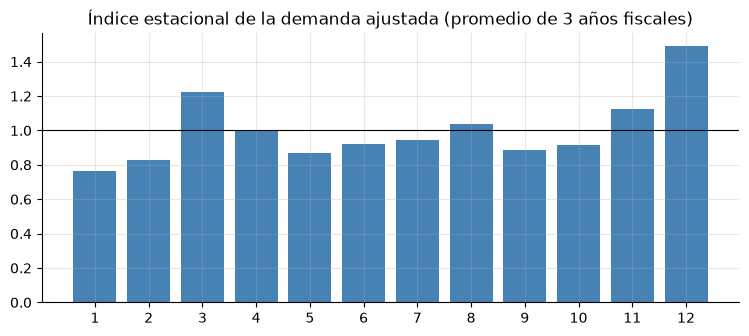

Factor del hueco (30-Sep → 11-Feb): 1.05 | factor del horizonte (11-Feb → 13-May): 1.03


In [4]:
def seasonal_index(adjusted: pd.DataFrame) -> pd.Series:
    total = adjusted.sum(axis=1).to_frame("u")
    total["fy"] = np.where(total.index.month >= 10, total.index.year + 1, total.index.year)
    t = total[total.groupby("fy")["u"].transform("size") == 12].copy()  # solo años fiscales completos
    t["idx"] = t["u"] / t.groupby("fy")["u"].transform("mean")
    return t.groupby(t.index.month)["idx"].mean().reindex(range(1, 13)).fillna(1.0)


def seasonal_factor(index: pd.Series, start: pd.Timestamp, end: pd.Timestamp) -> float:
    # Promedio del índice sobre los días del intervalo [start, end)
    days = pd.date_range(start, end - pd.Timedelta(days=1), freq="D")
    return float(index.reindex(days.month).mean())


idx_estacional = seasonal_index(hist.adjusted)
sf_hueco = seasonal_factor(idx_estacional, fechas.cutoff + pd.Timedelta(days=1), fechas.arrival)
sf_horizonte = seasonal_factor(idx_estacional, fechas.arrival, fechas.next_arrival)

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(idx_estacional.index, idx_estacional.values, color="steelblue")
ax.axhline(1, color="k", lw=0.8)
ax.set_xticks(range(1, 13))
ax.set_title("Índice estacional de la demanda ajustada (promedio de 3 años fiscales)")
plt.show()
print(
    f"Factor del hueco ({fechas.cutoff:%d-%b} → {fechas.arrival:%d-%b}): {sf_hueco:.2f} | factor del horizonte ({fechas.arrival:%d-%b} → {fechas.next_arrival:%d-%b}): {sf_horizonte:.2f}"
)

Factor del hueco ≈ 1.05 (incluye noviembre-diciembre); horizonte ≈ 1.0. Poco efecto en el pedido.

## 5. Posición de inventario cuando llegue el pedido
Stock al corte + tránsito − demanda del hueco − **sustitución entrante**, nunca negativa (S1.8).

La sustitución entrante recoge que, mientras Corolla Cross y Rush estén en cero, sus clientes seguirán comprando RAV4 y Raize. Se estima con la tasa histórica de sustitución por mes de quiebre.

In [5]:
def substitution_inflow(hist, index, gap_months, coverage) -> pd.Series:
    # Unidades que cada modelo receptor venderá en el hueco por sustitución, mientras su donante esté en cero:
    # tasa histórica por mes de quiebre del donante × meses de quiebre esperados del donante antes de la llegada
    inflow = pd.Series(0.0, index=index)
    censored_months = hist.censored.sum()
    for (donor, recv), units in hist.pairs.items():
        if donor in inflow.index and recv in inflow.index and censored_months[donor] > 0:
            rate = units / censored_months[donor]
            inflow[recv] += rate * max(0.0, gap_months - coverage[donor])
    return inflow


def position_table(d, demanda, fechas, sf_hueco, hist) -> pd.DataFrame:
    cutoff_month = fechas.cutoff.to_period("M")
    stock = d.inventory[d.inventory["month"] == cutoff_month].groupby("Modelo")["Unidades"].sum()
    transito = d.orders[d.orders["Estado"] == "En tránsito"]
    eta = transito["Fecha estimada de llegada"]
    t = demanda[["Demanda mensual"]].copy()
    t["Stock al corte"] = stock.reindex(t.index).fillna(0)
    t["En tránsito"] = (
        transito[eta <= fechas.arrival].groupby("Modelo")["Unidades"].sum().reindex(t.index).fillna(0)
    )
    t[
        "Tránsito en el horizonte"
    ] = (  # llega después que este pedido pero antes que el siguiente: se descuenta del pedido
        transito[(eta > fechas.arrival) & (eta <= fechas.next_arrival)]
        .groupby("Modelo")["Unidades"]
        .sum()
        .reindex(t.index)
        .fillna(0)
    )
    t["Demanda hasta la llegada"] = t["Demanda mensual"] * fechas.gap_months * sf_hueco
    t["Meses de cobertura hoy"] = (t["Stock al corte"] + t["En tránsito"]) / (t["Demanda mensual"] * sf_hueco)
    t["Sustitución entrante en el hueco"] = substitution_inflow(
        hist, t.index, fechas.gap_months, t["Meses de cobertura hoy"]
    )
    t["Posición al llegar"] = (
        t["Stock al corte"]
        + t["En tránsito"]
        - t["Demanda hasta la llegada"]
        - t["Sustitución entrante en el hueco"]
    ).clip(lower=0)
    t["Venta no atendible en el hueco"] = (
        t["Demanda hasta la llegada"] - t["Stock al corte"] - t["En tránsito"]
    ).clip(lower=0)
    return t


posicion = position_table(d, demanda, fechas, sf_hueco, hist)
display(
    posicion.sort_values("Meses de cobertura hoy")
    .style.format("{:,.1f}")
    .background_gradient(subset=["Meses de cobertura hoy"], cmap="RdYlGn", vmin=0, vmax=8)
)
no_atendible = posicion["Venta no atendible en el hueco"]
sust_entrante = posicion["Sustitución entrante en el hueco"]
print(
    f"Hueco de {fechas.gap_months:.1f} meses. Unidades que no se podrán vender antes de que llegue el pedido: {no_atendible.sum():.0f} "
    f"({', '.join(f'{m} {v:.0f}' for m, v in no_atendible[no_atendible > 0].sort_values(ascending=False).items())}). "
    f"De ellas, ~{sust_entrante.sum():.0f} se venderán como otro modelo por sustitución "
    f"({', '.join(f'{m} {v:.0f}' for m, v in sust_entrante[sust_entrante >= 1].sort_values(ascending=False).items())}); "
    f"el resto se pierde. Tránsito con ETA posterior a la llegada del pedido: {posicion['Tránsito en el horizonte'].sum():.0f} unidades."
)

# ¿Cuánto se pierde ya en el primer mes del hueco, antes de que cierre la ventana? Modelos en cero cuyo tránsito llega después
primer_mes = (fechas.cutoff + pd.Timedelta(days=1)).to_period("M")
_tr = d.orders[d.orders["Estado"] == "En tránsito"]
transito_primer_mes = (
    _tr[_tr["Fecha estimada de llegada"].dt.to_period("M") == primer_mes]
    .groupby("Modelo")["Unidades"]
    .sum()
    .reindex(posicion.index)
    .fillna(0)
)
en_cero_ya = (posicion["Stock al corte"] == 0) & (transito_primer_mes == 0)
perdida_primer_mes = float(
    (posicion.loc[en_cero_ya, "Demanda mensual"] * idx_estacional[primer_mes.month]).sum()
)
print(
    f"Unas {perdida_primer_mes:.0f} de esas unidades se pierden ya en {MESES_ES[primer_mes.month]}-{primer_mes.year}, antes del cierre de la ventana: "
    f"{', '.join(en_cero_ya.index[en_cero_ya])} están en cero y su tránsito llega después. Ningún pedido las rescata."
)

,Demanda mensual,Stock al corte,En tránsito,Tránsito en el horizonte,Demanda hasta la llegada,Meses de cobertura hoy,Sustitución entrante en el hueco,Posición al llegar,Venta no atendible en el hueco
Rush,10.8,0.0,12.0,0.0,49.9,1.1,0.0,0.0,37.9
Corolla Cross,25.7,0.0,30.0,0.0,119.1,1.1,0.0,0.0,89.1
Yaris Cross,16.8,0.0,24.0,0.0,78.1,1.4,0.0,0.0,54.1
Fortuner,8.9,20.0,20.0,0.0,41.4,4.3,0.8,0.0,1.4
Land Cruiser Prado,3.4,4.0,12.0,0.0,15.9,4.4,0.0,0.1,0.0
Corolla,8.2,23.0,19.0,0.0,37.9,4.9,1.8,2.3,0.0
Hiace,6.2,20.0,15.0,0.0,28.6,5.4,0.0,6.4,0.0
Raize,7.3,20.0,24.0,0.0,34.0,5.7,7.1,2.9,0.0
Hilux,34.5,135.0,103.0,0.0,160.1,6.5,0.0,77.9,0.0
Yaris,13.8,41.0,64.0,0.0,63.8,7.2,1.2,40.0,0.0


Hueco de 4.4 meses. Unidades que no se podrán vender antes de que llegue el pedido: 183 (Corolla Cross 89, Yaris Cross 54, Rush 38, Fortuner 1). De ellas, ~24 se venderán como otro modelo por sustitución (RAV4 14, Raize 7, Corolla 2, Yaris 1); el resto se pierde. Tránsito con ETA posterior a la llegada del pedido: 0 unidades.
Unas 49 de esas unidades se pierden ya en oct-2026, antes del cierre de la ventana: Corolla Cross, Yaris Cross, Rush están en cero y su tránsito llega después. Ningún pedido las rescata.


- **Corolla Cross, Yaris Cross y Rush están en cero y vuelven a quebrar hacia diciembre** tras el tránsito de noviembre (1.1–1.4 meses de cobertura para un hueco de 4.4): ~183 unidades que este pedido no puede rescatar, de las que ~50 se pierden ya en octubre y ~24 se venderán como otro modelo. Solo un pedido especial fuera de ventana evitaría las de diciembre a febrero; conviene plantearlo a fábrica.
- **Fortuner, Land Cruiser Prado y Corolla** llegan a febrero casi en cero.
- **Hilux y Yaris** atraviesan el hueco sin quebrar y llegan con ~2–3 meses de demanda (78 y 40 unidades).
- **RAV4** parece holgada (56 unidades), pero absorbe clientes de Corolla Cross y llega casi en cero.

## 6. Stock de seguridad: costo de faltar frente a costo de sobrar
Faltar cuesta el margen; sobrar cuesta tres meses más de plan piso y el descuento por antigüedad. Su cociente da el nivel de servicio de cada modelo. Se suma una reserva por el 12 % que llega tarde.

*Supuestos S1.9, S1.10 (ver §1).*

In [6]:
def critical_ratio(economics: pd.DataFrame) -> pd.DataFrame:
    e = economics
    margin = e["Precio promedio (USD)"] * e["Margen bruto %"]
    discount = pd.Series({m: END_OF_LIFE.get(m, LEFTOVER_DISCOUNT) for m in e.index})
    overstock = (
        LEFTOVER_EXTRA_MONTHS * e["Costo financiero mensual por unidad (USD)"]
        + discount * e["Precio promedio (USD)"]
    )
    cr = margin / (margin + overstock)
    z = cr.map(lambda p: NormalDist().inv_cdf(float(p)))
    z[list(END_OF_LIFE)] = 0.0  # S1.10 · ver §1: sin stock de seguridad en la última ventana
    return pd.DataFrame(
        {
            "Margen por unidad (USD)": margin,
            "Costo de una unidad sobrante (USD)": overstock,
            "Nivel de servicio objetivo": cr,
            "z": z,
        }
    )


def safety_stock(demanda, econ, fechas, sf_horizonte, months=None, sigma=None) -> pd.Series:
    # months: meses de incertidumbre que cubre la seguridad (por defecto el horizonte); sigma: desviación mensual
    # alternativa (por defecto la de la demanda ajustada). Solo la sensibilidad (§9) los cambia.
    eol = demanda.index.isin(END_OF_LIFE)
    months = fechas.horizon_months if months is None else months
    sigma = demanda["Desv. mensual"] if sigma is None else sigma
    variabilidad = econ["z"] * sigma * np.sqrt(months)
    llegada_tardia = np.where(
        eol, 0.0, LATE_SHARE * LATE_DELAY_MONTHS * demanda["Demanda mensual"] * sf_horizonte
    )
    return (variabilidad + llegada_tardia).rename("Stock de seguridad")


economia = critical_ratio(d.economics)
seguridad = safety_stock(demanda, economia, fechas, sf_horizonte)
economia.join(demanda["Desv. mensual"]).join(seguridad).style.format(
    {
        "Margen por unidad (USD)": "{:,.0f}",
        "Costo de una unidad sobrante (USD)": "{:,.0f}",
        "Nivel de servicio objetivo": "{:.0%}",
        "z": "{:.2f}",
        "Desv. mensual": "{:.1f}",
        "Stock de seguridad": "{:.1f}",
    }
).background_gradient(subset=["Nivel de servicio objetivo"], cmap="RdYlGn", vmin=0.3, vmax=0.8)

,Margen por unidad (USD),Costo de una unidad sobrante (USD),Nivel de servicio objetivo,z,Desv. mensual,Stock de seguridad
Modelo,,,,,,
Hilux,"5,681","2,774",67%,0.45,11.0,12.7
Fortuner,"6,665","3,542",65%,0.39,3.1,3.2
Corolla,"2,449","1,757",58%,0.21,2.6,1.9
Corolla Cross,"3,971","2,110",65%,0.39,9.4,9.5
Yaris,"1,483","1,378",52%,0.05,3.6,2.0
Yaris Cross,"3,042","1,769",63%,0.34,5.8,5.4
RAV4,"4,269","5,307",45%,0.00,3.8,0.0
Land Cruiser Prado,"8,681","5,053",63%,0.34,2.0,1.6
Rush,"2,064","1,674",55%,0.13,3.8,2.2


Niveles de servicio moderados (50–70 %) por los márgenes bajos: **Yaris y Raize** ~50 % (casi sin seguridad); **Hilux, Fortuner y Corolla Cross** 65–67 %. **RAV4** queda por debajo del 50 % y no lleva seguridad.

## 7. El pedido
Pedido = demanda del horizonte + seguridad − posición al llegar, redondeado a **0 o ≥ mínimo, en múltiplos del lote** (S1.9). RAV4 se redondea hacia abajo (S1.10).

,Demanda del horizonte,Posición al llegar,Stock de seguridad,Pedido bruto,Mínimo,Múltiplo,Pedido,Capital (USD),Cobertura tras el pedido (meses)
Hilux,105.8,77.9,12.7,40.6,12,6,42,"USD 1,596,840",3.4
Fortuner,27.3,0.0,3.2,30.5,8,4,32,"USD 1,564,160",3.5
Corolla,25.0,2.3,1.9,24.7,6,6,24,"USD 594,240",3.1
Corolla Cross,78.7,0.0,9.5,88.2,12,6,90,"USD 2,620,800",3.4
Yaris,42.2,40.0,2.0,4.2,16,8,0,USD 0,2.8
Yaris Cross,51.6,0.0,5.4,57.1,12,6,60,"USD 1,476,600",3.5
RAV4,22.0,9.2,0.0,12.8,4,4,12,"USD 461,040",2.9
Land Cruiser Prado,10.5,0.1,1.6,11.9,2,2,12,"USD 842,880",3.5
Rush,33.0,0.0,2.2,35.1,8,4,36,"USD 854,640",3.3
Hiace,18.9,6.4,2.8,15.4,3,3,15,"USD 584,250",3.4


**Pedido total: 341 unidades, USD 11.0 millones de capital comprometido** (el pedido de jul-2026 fue de 347 unidades).

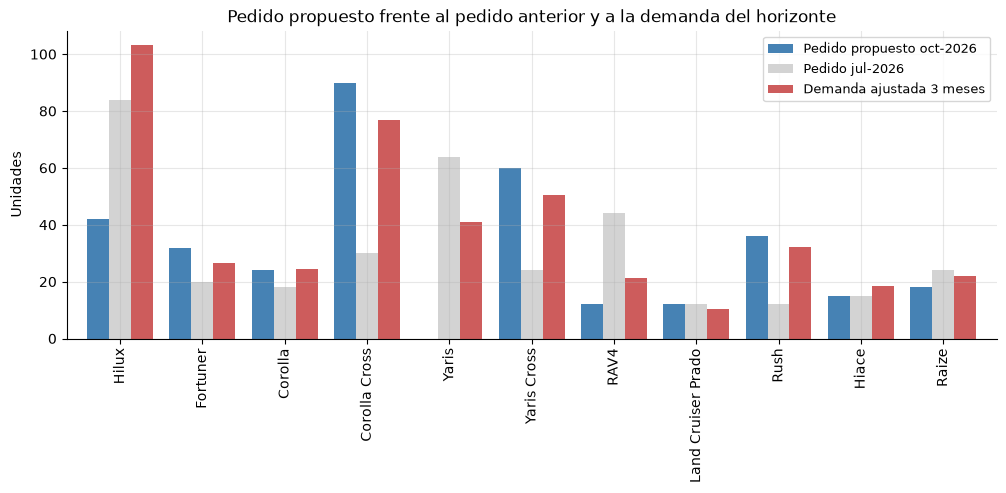

In [7]:
def round_to_rules(raw: float, min_order: int, lot: int, floor: bool = False) -> int:
    if raw <= 0:
        return 0
    if floor:
        q = int(np.floor(raw / lot)) * lot
        return q if q >= min_order else 0
    q = int(round(raw / lot)) * lot
    if q < min_order:
        return min_order if raw >= min_order / 2 else 0
    return q


def order_table(
    d, demanda, fechas, sf_hueco, sf_horizonte, hist, ss_months=None, ss_sigma=None
) -> pd.DataFrame:
    # Encadena posición, seguridad y redondeo; se reutiliza en la sensibilidad (§9)
    econ = critical_ratio(d.economics)
    t = position_table(d, demanda, fechas, sf_hueco, hist)
    t["Desv. mensual"] = demanda["Desv. mensual"]
    t["Demanda del horizonte"] = t["Demanda mensual"] * fechas.horizon_months * sf_horizonte
    t["Nivel de servicio"] = econ["Nivel de servicio objetivo"]
    t["Stock de seguridad"] = safety_stock(demanda, econ, fechas, sf_horizonte, ss_months, ss_sigma)
    t["Pedido bruto"] = (
        t["Demanda del horizonte"]
        + t["Stock de seguridad"]
        - t["Posición al llegar"]
        - t["Tránsito en el horizonte"]
    )
    t["Mínimo"] = d.rules["min_order"].reindex(t.index)
    t["Múltiplo"] = d.rules["lot_multiple"].reindex(t.index)
    t["Pedido"] = [
        round_to_rules(r, int(mn), int(lt), floor=m in END_OF_LIFE)
        for m, r, mn, lt in zip(t.index, t["Pedido bruto"], t["Mínimo"], t["Múltiplo"], strict=True)
    ]
    t["Capital (USD)"] = t["Pedido"] * d.economics["Costo unitario promedio (USD)"].reindex(t.index)
    t["Cobertura tras el pedido (meses)"] = (t["Posición al llegar"] + t["Pedido"]) / (
        t["Demanda mensual"] * sf_horizonte
    )
    return t


pedido = order_table(d, demanda, fechas, sf_hueco, sf_horizonte, hist)
cols_ped = [
    "Demanda del horizonte",
    "Posición al llegar",
    "Stock de seguridad",
    "Pedido bruto",
    "Mínimo",
    "Múltiplo",
    "Pedido",
    "Capital (USD)",
    "Cobertura tras el pedido (meses)",
]
display(
    pedido[cols_ped]
    .style.format(
        {c: "{:,.1f}" for c in cols_ped}
        | {"Mínimo": "{:.0f}", "Múltiplo": "{:.0f}", "Pedido": "{:.0f}", "Capital (USD)": "USD {:,.0f}"}
    )
    .background_gradient(subset=["Pedido"], cmap="Blues")
)
# Pedido de la ventana anterior (un trimestre antes del cierre), para comparar
ventana_previa = fechas.window_close - pd.DateOffset(months=3)
etiqueta_previa = f"{MESES_ES[ventana_previa.month]}-{ventana_previa.year}"
etiqueta_actual = f"{MESES_ES[fechas.window_close.month]}-{fechas.window_close.year}"
jul = (
    d.orders[d.orders["order_quarter"] == ventana_previa.to_period("Q")]
    .groupby("Modelo")["Unidades"]
    .sum()
    .reindex(MODELOS)
    .fillna(0)
)
display(
    Markdown(
        f"**Pedido total: {pedido['Pedido'].sum():.0f} unidades, USD {pedido['Capital (USD)'].sum() / 1e6:,.1f} millones de capital comprometido** "
        f"(el pedido de {etiqueta_previa} fue de {jul.sum():.0f} unidades)."
    )
)
comp = pd.DataFrame(
    {
        f"Pedido propuesto {etiqueta_actual}": pedido["Pedido"],
        f"Pedido {etiqueta_previa}": jul,
        "Demanda ajustada 3 meses": pedido["Demanda mensual"] * fechas.horizon_months,
    }
)
ax = comp.plot(kind="bar", figsize=(12, 4), color=["steelblue", "lightgray", "indianred"], width=0.8)
ax.set_title("Pedido propuesto frente al pedido anterior y a la demanda del horizonte")
ax.set_ylabel("Unidades")
plt.show()

In [8]:
# Lectura automática del pedido: cómo se llega a cada cifra
filas = []
for m, row in pedido.iterrows():
    if row["Pedido"] == 0:
        if row["Pedido bruto"] <= 0:
            motivo = f"posición al llegar de {row['Posición al llegar']:.0f} u. cubre la demanda del horizonte ({row['Demanda del horizonte']:.0f} u.) y la seguridad"
        else:
            motivo = (
                f"posición {row['Posición al llegar']:.0f} frente a demanda {row['Demanda del horizonte']:.0f} + seguridad {row['Stock de seguridad']:.0f}: "
                f"faltan {row['Pedido bruto']:.0f} u., menos de la mitad del mínimo ({row['Mínimo']:.0f}); pedir el mínimo dejaría ~{row['Mínimo'] - row['Pedido bruto']:.0f} u. sobrantes"
            )
        if m in END_OF_LIFE:
            motivo += "; última ventana de la generación: sin seguridad y redondeo hacia abajo"
    else:
        transito_h = (
            f" − tránsito en horizonte {row['Tránsito en el horizonte']:.0f}"
            if row["Tránsito en el horizonte"] > 0
            else ""
        )
        motivo = (
            f"demanda {row['Demanda del horizonte']:.0f} + seguridad {row['Stock de seguridad']:.0f} − posición {row['Posición al llegar']:.0f}{transito_h} "
            f"= {row['Pedido bruto']:.0f} → {row['Pedido']:.0f} (mín. {row['Mínimo']:.0f}, múltiplo {row['Múltiplo']:.0f})"
        )
        if row["Sustitución entrante en el hueco"] >= 1:
            motivo += f"; la posición descuenta {row['Sustitución entrante en el hueco']:.0f} u. de sustitución entrante"
    filas.append((m, int(row["Pedido"]), int(jul[m]), motivo))
pd.DataFrame(filas, columns=["Modelo", "Pedido", f"Pedido {etiqueta_previa}", "Cómo se llega"]).style.hide(
    axis="index"
)

Modelo,Pedido,Pedido jul-2026,Cómo se llega
Hilux,42,84,"demanda 106 + seguridad 13 − posición 78 = 41 → 42 (mín. 12, múltiplo 6)"
Fortuner,32,20,"demanda 27 + seguridad 3 − posición 0 = 31 → 32 (mín. 8, múltiplo 4)"
Corolla,24,18,"demanda 25 + seguridad 2 − posición 2 = 25 → 24 (mín. 6, múltiplo 6); la posición descuenta 2 u. de sustitución entrante"
Corolla Cross,90,30,"demanda 79 + seguridad 10 − posición 0 = 88 → 90 (mín. 12, múltiplo 6)"
Yaris,0,64,"posición 40 frente a demanda 42 + seguridad 2: faltan 4 u., menos de la mitad del mínimo (16); pedir el mínimo dejaría ~12 u. sobrantes"
Yaris Cross,60,24,"demanda 52 + seguridad 5 − posición 0 = 57 → 60 (mín. 12, múltiplo 6)"
RAV4,12,44,"demanda 22 + seguridad 0 − posición 9 = 13 → 12 (mín. 4, múltiplo 4); la posición descuenta 14 u. de sustitución entrante"
Land Cruiser Prado,12,12,"demanda 10 + seguridad 2 − posición 0 = 12 → 12 (mín. 2, múltiplo 2)"
Rush,36,12,"demanda 33 + seguridad 2 − posición 0 = 35 → 36 (mín. 8, múltiplo 4)"
Hiace,15,15,"demanda 19 + seguridad 3 − posición 6 = 15 → 15 (mín. 3, múltiplo 3)"


- **Los tres modelos en quiebre concentran más de la mitad del pedido:** llegan en cero y su demanda real es 30–50 % mayor que su venta. El pedido de julio repitió 30 / 24 / 12 mientras se agotaban.
- **Hilux baja a la mitad** del pedido de julio: le sobra volumen y le faltan versiones (§8).
- **Yaris en cero** (llega con 40 unidades para una demanda de 42 más 2 de seguridad: el faltante de ~4 no llega a la mitad del mínimo de 16 y pedirlo dejaría ~12 sobrantes); **RAV4 solo 12**, y solo si Corolla Cross sigue en cero en el hueco. Si fábrica adelanta Corolla Cross, RAV4 vuelve a cero (§9).
- **Menos capital** que el pedido de julio, porque deja de alimentar modelos con 5–7 meses de cobertura.

## 8. Mezcla por versión
El pedido de cada modelo se reparte según el **faltante** de cada versión: demanda (venta + leads perdidos de esa versión) hasta el final del horizonte, menos stock y tránsito. Las versiones sin faltante reciben cero. La necesidad por versión solo sirve para repartir el pedido del modelo: incluye todas las pérdidas de la versión y no lleva estacionalidad ni sustitución, así que no suma la demanda del modelo.

In [9]:
def version_split(d, pedido, fechas, window=DEMAND_WINDOW_MONTHS) -> pd.DataFrame:
    start = fechas.cutoff - pd.DateOffset(months=window)
    sales = d.base_sales[d.base_sales["Fecha"] > start].groupby(["Modelo", "Versión"])["Unidades"].sum()
    leads = d.leads[
        ~d.leads["special_fleet"] & d.leads["no_availability"] & (d.leads["Fecha cierre"] > start)
    ]
    lost = (
        leads.dropna(subset=["Versión de interés"])
        .groupby(["Modelo de interés", "Versión de interés"])["Unidades"]
        .sum()
    )
    lost.index.names = ["Modelo", "Versión"]
    v = pd.DataFrame({"Demanda 12m": sales.add(lost, fill_value=0)}).fillna(0)
    v["Stock al corte"] = (
        d.inventory[d.inventory["month"] == fechas.cutoff.to_period("M")]
        .groupby(["Modelo", "Versión"])["Unidades"]
        .sum()
        .reindex(v.index)
        .fillna(0)
    )
    v["En tránsito"] = (
        d.orders[d.orders["Estado"] == "En tránsito"]
        .groupby(["Modelo", "Versión"])["Unidades"]
        .sum()
        .reindex(v.index)
        .fillna(0)
    )
    v["Necesidad hasta fin del horizonte"] = (
        v["Demanda 12m"] / window * (fechas.gap_months + fechas.horizon_months)
    )
    v["Faltante"] = (v["Necesidad hasta fin del horizonte"] - v["Stock al corte"] - v["En tránsito"]).clip(
        lower=0
    )
    v["Pedido"] = 0
    for model, q in pedido["Pedido"].items():
        if q <= 0 or model not in v.index.get_level_values(0):
            continue
        sub = v.loc[model]
        weights = sub["Faltante"] if sub["Faltante"].sum() > 0 else sub["Demanda 12m"]
        raw = q * weights / weights.sum()
        alloc = np.floor(raw).astype(int)
        for ver in (raw - alloc).sort_values(ascending=False).index[: int(q - alloc.sum())]:  # resto mayor
            alloc[ver] += 1
        v.loc[[(model, ver) for ver in alloc.index], "Pedido"] = alloc.values
    return v[v.index.get_level_values(0).isin(pedido.index[pedido["Pedido"] > 0])]


versiones = version_split(d, pedido, fechas)
display(
    versiones.style.format(
        {c: "{:,.1f}" for c in versiones.columns} | {"Pedido": "{:.0f}"}
    ).background_gradient(subset=["Pedido"], cmap="Blues")
)
ceros = versiones[(versiones["Pedido"] == 0) & (versiones["Stock al corte"] + versiones["En tránsito"] > 0)]
print("Versiones que no se piden pese a pedirse el modelo (stock + tránsito ya cubren su demanda):")
for (m, ver), row in ceros.iterrows():
    print(
        f"  {m} · {ver}: {row['Stock al corte']:.0f} en patio + {row['En tránsito']:.0f} en tránsito para {row['Demanda 12m'] / 12:.1f} u./mes"
    )

Versiones que no se piden pese a pedirse el modelo (stock + tránsito ya cubren su demanda):
  Corolla · SEG Híbrido: 20 en patio + 5 en tránsito para 2.2 u./mes
  Hiace · Commuter Techo Alto: 10 en patio + 3 en tránsito para 1.4 u./mes
  Hiace · Panel: 8 en patio + 6 en tránsito para 1.9 u./mes
  Hilux · Cabina Sencilla 4x4 MT: 51 en patio + 21 en tránsito para 5.3 u./mes
  Land Cruiser Prado · VX: 0 en patio + 4 en tránsito para 0.6 u./mes


**Hilux Cabina Sencilla 4x4 MT y Corolla SEG Híbrido quedan en cero** (ya tienen ~10 y ~9 meses de cobertura solo con el patio); el pedido de Hilux va a **SRV 4x4 AT** y Doble Cabina. El color sigue el mix histórico (ningún color pasa del 20 %).

## 9. Sensibilidad
¿Cuánto cambia el pedido si la demanda o el lead time son distintos?

In [10]:
escenarios = {"Base": pedido["Pedido"]}

dem_alt = demanda.copy()
dem_alt["Demanda mensual"] = dem_alt["Demanda mensual (solo meses con stock)"]
escenarios["Demanda = promedio de meses con stock"] = order_table(
    d, dem_alt, fechas, sf_hueco, sf_horizonte, hist
)["Pedido"]

for k, nombre in [(0.8, "Demanda −20 %"), (1.2, "Demanda +20 %")]:
    dem_k = demanda.copy()
    dem_k["Demanda mensual"] *= k
    escenarios[nombre] = order_table(d, dem_k, fechas, sf_hueco, sf_horizonte, hist)["Pedido"]

fechas_122 = cycle_dates(lead_time_days=122)
sf_h_122 = seasonal_factor(idx_estacional, fechas_122.arrival, fechas_122.next_arrival)
sf_g_122 = seasonal_factor(idx_estacional, fechas_122.cutoff + pd.Timedelta(days=1), fechas_122.arrival)
escenarios["Lead time 4 meses (122 d)"] = order_table(d, demanda, fechas_122, sf_g_122, sf_h_122, hist)[
    "Pedido"
]

# Si fábrica acepta el adelanto de Corolla Cross y Rush (§12, rec. 1), los donantes no quiebran y nadie recibe sustitución
hist_sin_sust = SimpleNamespace(**{**vars(hist), "pairs": pd.Series(dtype=float)})
escenarios["Sin sustitución en el hueco"] = order_table(
    d, demanda, fechas, sf_hueco, sf_horizonte, hist_sin_sust
)["Pedido"]

# Los dos atajos de S1.9: incertidumbre sobre hueco + horizonte en vez de solo horizonte, y desviación sin estacionalidad
ss_total = fechas.gap_months + fechas.horizon_months
escenarios["Seguridad sobre hueco + horizonte"] = order_table(
    d, demanda, fechas, sf_hueco, sf_horizonte, hist, ss_months=ss_total
)["Pedido"]
ult_12 = hist.adjusted.iloc[-DEMAND_WINDOW_MONTHS:]
desv_sin_estacionalidad = ult_12.div(idx_estacional.reindex(ult_12.index.month).to_numpy(), axis=0).std(
    ddof=1
)
escenarios["Desv. sin estacionalidad"] = order_table(
    d, demanda, fechas, sf_hueco, sf_horizonte, hist, ss_sigma=desv_sin_estacionalidad
)["Pedido"]
escenarios["Ambos ajustes de S1.9"] = order_table(
    d, demanda, fechas, sf_hueco, sf_horizonte, hist, ss_months=ss_total, ss_sigma=desv_sin_estacionalidad
)["Pedido"]

sens = pd.DataFrame(escenarios)
sens.loc["Total"] = sens.sum()
sens.style.format("{:.0f}").background_gradient(subset=pd.IndexSlice[MODELOS, :], cmap="Blues", axis=None)

,Base,Demanda = promedio de meses con stock,Demanda −20 %,Demanda +20 %,Lead time 4 meses (122 d),Sin sustitución en el hueco,Seguridad sobre hueco + horizonte,Desv. sin estacionalidad,Ambos ajustes de S1.9
Hilux,42,42,0,96,60,42,48,36,42
Fortuner,32,32,20,36,32,32,32,32,32
Corolla,24,24,12,30,30,24,24,24,24
Corolla Cross,90,90,72,102,90,90,90,84,90
Yaris,0,0,0,24,16,0,0,0,0
Yaris Cross,60,72,48,66,60,60,60,54,54
RAV4,12,24,0,24,16,0,12,12,12
Land Cruiser Prado,12,12,6,14,12,12,12,12,12
Rush,36,36,28,40,36,36,36,36,36
Hiace,15,15,6,24,18,15,18,15,15


- Los modelos en quiebre se mueven en proporción a la demanda estimada.
- **Hilux es el más sensible** (de 0 a 96 unidades con ±20 % de demanda): conviene revisarlo con la gerencia antes de enviar.
- Con el lead time de 4 meses el hueco crece 18 días y el total sube; por eso se usa el lead time observado.
- Si fábrica adelanta Corolla Cross y Rush, RAV4 vuelve a cero y Raize baja.

- Los dos atajos de S1.9 se compensan: medir la incertidumbre sobre hueco + horizonte sube el total a 350 (Hilux 48, Hiace 18) y quitar la estacionalidad de la desviación lo baja a 323 (Hilux, Corolla Cross y Yaris Cross −6 cada uno); con ambos a la vez queda en 335.

Lo que más pesa es la **demanda estimada de los modelos en quiebre**, y por eso se hace explícita (§3).

## 10. Resumen visual para la gerencia
Pedido frente a demanda por modelo, y cobertura antes y después del pedido. Se exportan a `outputs/figuras/`.


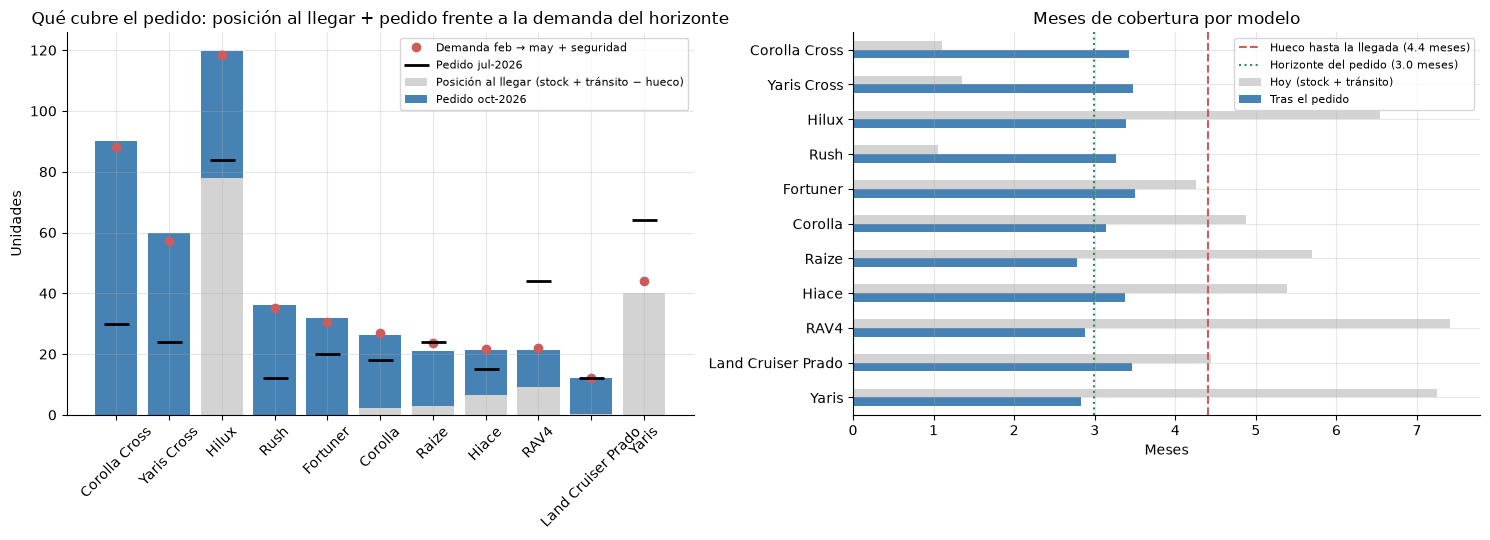

Exportado: outputs/figuras/caso1_resumen_gerencia_2026-10.png


In [11]:
FIGURAS = OUTPUTS / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)
orden = pedido["Pedido"].sort_values(ascending=False).index
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

ax = axes[0]
ax.bar(
    orden,
    pedido.loc[orden, "Posición al llegar"],
    color="lightgray",
    label="Posición al llegar (stock + tránsito − hueco)",
)
ax.bar(
    orden,
    pedido.loc[orden, "Pedido"],
    bottom=pedido.loc[orden, "Posición al llegar"],
    color="steelblue",
    label=f"Pedido {etiqueta_actual}",
)
ax.plot(
    orden,
    (pedido["Demanda del horizonte"] + pedido["Stock de seguridad"]).loc[orden],
    "o",
    color="indianred",
    label="Demanda feb → may + seguridad",
)
ax.plot(orden, jul[orden], "_", color="k", markersize=18, mew=2, label=f"Pedido {etiqueta_previa}")
ax.set_title("Qué cubre el pedido: posición al llegar + pedido frente a la demanda del horizonte")
ax.set_ylabel("Unidades")
ax.tick_params(axis="x", rotation=45)
ax.legend(fontsize=8)

ax = axes[1]
cobertura = pd.DataFrame(
    {
        "Hoy (stock + tránsito)": pedido["Meses de cobertura hoy"],
        "Tras el pedido": pedido["Cobertura tras el pedido (meses)"],
    }
).loc[orden]
cobertura.plot(kind="barh", ax=ax, color=["lightgray", "steelblue"])
ax.axvline(
    fechas.gap_months,
    color="indianred",
    ls="--",
    label=f"Hueco hasta la llegada ({fechas.gap_months:.1f} meses)",
)
ax.axvline(
    fechas.horizon_months,
    color="seagreen",
    ls=":",
    label=f"Horizonte del pedido ({fechas.horizon_months:.1f} meses)",
)
ax.set_title("Meses de cobertura por modelo")
ax.set_xlabel("Meses")
ax.invert_yaxis()
ax.legend(fontsize=8)
plt.tight_layout()
ruta_fig = FIGURAS / f"caso1_resumen_gerencia_{fechas.window_close:%Y-%m}.png"
fig.savefig(ruta_fig, dpi=150, bbox_inches="tight")
plt.show()
print("Exportado:", ruta_fig.relative_to(ROOT))

## 11. Exportar el pedido
Tablas por modelo y por versión para el planificador y para el registro del ciclo: en la ventana siguiente se comparan con la demanda real.

In [12]:
OUTPUTS.mkdir(parents=True, exist_ok=True)
etiqueta = f"{fechas.window_close:%Y-%m}"
rutas = [OUTPUTS / f"pedido_{etiqueta}_por_modelo.csv", OUTPUTS / f"pedido_{etiqueta}_por_version.csv"]
pedido.round(2).to_csv(rutas[0])
versiones.round(2).to_csv(rutas[1])
print("Exportado:", *[p.relative_to(ROOT) for p in rutas])

Exportado: outputs/pedido_2026-10_por_modelo.csv outputs/pedido_2026-10_por_version.csv


## 12. Sistema de pedidos: cómo funcionaría en cada ciclo

Este notebook **es** el prototipo: calcula el pedido por modelo y por versión a partir del Excel y se vuelve a ejecutar en cada ventana trimestral cambiando dos fechas.

**Flujo** (una semana antes de cada cierre de ventana):

1. El área de datos deja el Excel actualizado en `data/raw/` y fija la fecha de corte y el cierre de ventana en `PARAMS` de `00_limpieza`.
2. `00_limpieza` valida y concilia (inventario = anterior + recepciones − facturas; modelos y sucursales dentro de catálogo; reglas de fábrica leídas de los comunicados) y **se detiene** si aparece un problema nuevo: otra grafía, un modelo fuera de catálogo, un comunicado que no se pudo interpretar.
3. Este notebook recalibra el lead time y la fracción de llegadas tardías desde la hoja *Pedidos*, calcula el pedido y exporta las tablas por modelo y por versión (§11) y la figura para la gerencia (§10).
4. El planificador revisa la tabla «cómo se llega» (§7), la mezcla por versión (§8) y la sensibilidad (§9), ajusta lo que los datos no saben (flotas comprometidas, lanzamientos, promociones) y envía el pedido a fábrica. El texto de la respuesta (§13) cita cifras de este ciclo (versiones a liquidar, meses del hueco) y se revisa con cada corrida.
5. En la ventana siguiente se compara la demanda proyectada con la real y se recalibran la fracción de demanda recuperable y el índice estacional.

**Cómo calcula:** calendario del ciclo con el lead time real (§2) → demanda ajustada por modelo: venta de 12 meses + pérdidas por disponibilidad y sustituciones solo en meses de quiebre (§3) → estacionalidad (§4) → posición al llegar el pedido: stock + tránsito − demanda del hueco − sustitución entrante, nunca negativa (§5) → stock de seguridad por modelo según el costo de faltar frente al de sobrar y el 12 % de llegadas tardías (§6) → pedido = demanda del horizonte + seguridad − posición, redondeado a los mínimos y múltiplos de fábrica (§7) → mezcla por versión según el faltante de cada una (§8).

**Datos que usa:** las siete hojas del Excel. *Ventas* (demanda base, sin flotas especiales), *Inventario* (stock al corte y antigüedad), *Leads* (pérdidas por disponibilidad y sustituciones entre modelos), *Pedidos* (tránsito, lead time, llegadas tardías), *Economía por modelo* (margen, costo financiero y descuento, de donde sale el nivel de servicio), *Comunicados* (mínimos, múltiplos, calendario, fin de generación) y *Diccionario*. **Datos que pediría:** inventario por VIN con fecha de llegada, ETA original y vigente por línea de pedido, pedidos de flota ya comprometidos para 2027 y el plan comercial del año.

**Cómo apoyaría la IA al planificador.** No calculando el número. El cálculo es determinista a propósito: con 36 meses por modelo (y menos por versión y sucursal) un modelo de aprendizaje automático aprende ruido; lo difícil del problema no es pronosticar una demanda plana con estacionalidad clara, sino corregir la demanda censurada, proyectar la posición de inventario y fijar el stock de seguridad por la economía de cada modelo, que es teoría de inventarios; y un pedido de ~USD 11 millones tiene que poder discutirse modelo por modelo con la gerencia. La IA apoya alrededor del cálculo:

- (a) **Leer los comunicados y extraer las reglas** (mínimos, múltiplos, calendario, fin de generación), que hoy se interpretan con reglas fijas que se rompen si cambia la redacción.
- (b) **Explicar cada pedido en lenguaje de negocio** a partir de las tablas intermedias (§7 ya lo hace con plantillas).
- (c) **Detectar anomalías en la base** antes de que entren al cálculo: precios en otra moneda, duplicados, grafías nuevas.
- (d) **Clasificar los motivos de pérdida del CRM** en texto libre: es la señal que convierte la venta perdida en pedido.

Todo lo que proponga pasa por las mismas validaciones que los notebooks (conciliación de inventario, recuentos, sensibilidad). Cuando el sistema haya registrado varios ciclos de demanda proyectada frente a real, un modelo de demanda agrupado (modelo × versión × sucursal) podría afinar la mezcla por versión; hoy su beneficio sería marginal frente a corregir bien la censura.

**Cómo se mediría** (por ciclo y por modelo):

| Métrica | Qué vigila | Hoy |
|---|---|---|
| Meses con stock en cero | quiebres | 3 modelos en cero al corte; 23 modelo-mes en 36 meses |
| Unidades perdidas por disponibilidad / venta | demanda censurada | 20 % en los últimos 12 meses |
| Unidades con más de 180 días en patio | sobrestock | 57 (Hilux Cabina Sencilla 34, Corolla SEG Híbrido 17, Yaris Hatchback S AT 6) |
| Error de la demanda proyectada frente a la real | calidad del pronóstico | se empieza a medir con este ciclo |
| Lead time real y fracción de unidades tardías | fiabilidad de fábrica | 104 días; 12 % tardías |
| Inventario / venta mensual (unidades) | eficiencia | ~2.3 meses de cobertura |

In [13]:
quiebre = posicion.index[
    posicion["Venta no atendible en el hueco"] >= 5
].tolist()  # modelos que se agotan claramente antes de la llegada
ceros = pedido.index[pedido["Pedido"] == 0].tolist()
top = pedido["Pedido"].sort_values(ascending=False)
sin_sust = escenarios["Sin sustitución en el hueco"]
receptores = [
    m for m in MODELOS if sin_sust[m] != pedido.at[m, "Pedido"]
]  # modelos cuyo pedido depende de la sustitución
viejas = d.inventory.loc[
    (d.inventory["month"] == fechas.cutoff.to_period("M")) & (d.inventory["age_days"] > 180), "Unidades"
].sum()
viejas_por_version = (
    d.inventory.loc[(d.inventory["month"] == fechas.cutoff.to_period("M")) & (d.inventory["age_days"] > 180)]
    .groupby(["Modelo", "Versión"])["Unidades"]
    .sum()
    .sort_values(ascending=False)
)
detalle_viejas = ", ".join(f"{m} {v} {int(u)}" for (m, v), u in viejas_por_version.items())
display(
    Markdown(
        f"""
## 13. Respuesta a la gerencia comercial

### Recomendación

**Pedir {pedido["Pedido"].sum():.0f} unidades (USD {pedido["Capital (USD)"].sum() / 1e6:,.1f} millones)** en la ventana del {fechas.window_close:%d-%b-%Y}, {abs(int(pedido["Pedido"].sum() - jul.sum()))} unidades {"menos" if pedido["Pedido"].sum() < jul.sum() else "más"} que el pedido de {etiqueta_previa} ({jul.sum():.0f}) pero repartidas de otra forma: {", ".join(f"{m} {int(q)}" for m, q in top[top > 0].items())}; **cero** en {", ".join(ceros)}. La tabla «cómo se llega» de §7 explica cada cifra.

1. **Concentrar el pedido en {", ".join(quiebre)}**, que se agotan antes de febrero y cuya demanda real supera en 30-50 % la venta registrada. Plantear a fábrica un adelanto o pedido especial para las ~{no_atendible.sum() - perdida_primer_mes:.0f} unidades que no se podrán atender entre que se agote el tránsito y llegue este pedido ({fechas.arrival:%d-%b-%Y}); otras ~{perdida_primer_mes:.0f} se pierden ya en {MESES_ES[primer_mes.month]}, porque esos modelos están en cero y su tránsito llega después, y ningún pedido las rescata. De las ~{no_atendible.sum():.0f} en total, unas {sust_entrante.sum():.0f} se venderán como otro modelo: la pérdida neta es ~{no_atendible.sum() - sust_entrante.sum():.0f}. Es la decisión más cara del ciclo.
2. **No pedir Yaris** este ciclo: llega a febrero con {pedido.at["Yaris", "Posición al llegar"]:.0f} unidades, el {pedido.at["Yaris", "Posición al llegar"] / pedido.at["Yaris", "Demanda del horizonte"]:.0%} de la demanda del horizonte, y el faltante de ~{pedido.at["Yaris", "Pedido bruto"]:.0f} no justifica el mínimo de {pedido.at["Yaris", "Mínimo"]:.0f}. **RAV4: solo {int(pedido.at["RAV4", "Pedido"])} unidades y condicionadas**: cubren los clientes que Corolla Cross le seguirá desplazando mientras esté en cero. Si fábrica acepta el adelanto del punto 1, baja {" y ".join(f"{m} a {int(sin_sust[m])}" for m in receptores)}. Cada unidad extra de la generación actual de RAV4 se liquidaría casi seguro con el 10 % de descuento sin apoyo de fábrica.
3. **Pedir las versiones correctas de Hilux** (SRV 4x4 AT y Doble Cabina) y cero Cabina Sencilla 4x4 MT y Corolla SEG Híbrido hasta liquidar las unidades con más de 180 días en patio ({int(viejas)}: {detalle_viejas}).
4. **Repetir este cálculo en cada ventana** con el sistema de §12 y medir el error de la demanda proyectada frente a la real: es la única forma de calibrar la fracción de demanda recuperable, que hoy es el supuesto con más peso.
"""
    )
)


## 13. Respuesta a la gerencia comercial

### Recomendación

**Pedir 341 unidades (USD 11.0 millones)** en la ventana del 30-Oct-2026, 6 unidades menos que el pedido de jul-2026 (347) pero repartidas de otra forma: Corolla Cross 90, Yaris Cross 60, Hilux 42, Rush 36, Fortuner 32, Corolla 24, Raize 18, Hiace 15, RAV4 12, Land Cruiser Prado 12; **cero** en Yaris. La tabla «cómo se llega» de §7 explica cada cifra.

1. **Concentrar el pedido en Corolla Cross, Yaris Cross, Rush**, que se agotan antes de febrero y cuya demanda real supera en 30-50 % la venta registrada. Plantear a fábrica un adelanto o pedido especial para las ~134 unidades que no se podrán atender entre que se agote el tránsito y llegue este pedido (11-Feb-2027); otras ~49 se pierden ya en oct, porque esos modelos están en cero y su tránsito llega después, y ningún pedido las rescata. De las ~183 en total, unas 24 se venderán como otro modelo: la pérdida neta es ~158. Es la decisión más cara del ciclo.
2. **No pedir Yaris** este ciclo: llega a febrero con 40 unidades, el 95% de la demanda del horizonte, y el faltante de ~4 no justifica el mínimo de 16. **RAV4: solo 12 unidades y condicionadas**: cubren los clientes que Corolla Cross le seguirá desplazando mientras esté en cero. Si fábrica acepta el adelanto del punto 1, baja RAV4 a 0 y Raize a 12. Cada unidad extra de la generación actual de RAV4 se liquidaría casi seguro con el 10 % de descuento sin apoyo de fábrica.
3. **Pedir las versiones correctas de Hilux** (SRV 4x4 AT y Doble Cabina) y cero Cabina Sencilla 4x4 MT y Corolla SEG Híbrido hasta liquidar las unidades con más de 180 días en patio (57: Hilux Cabina Sencilla 4x4 MT 34, Corolla SEG Híbrido 17, Yaris Hatchback S AT 6).
4. **Repetir este cálculo en cada ventana** con el sistema de §12 y medir el error de la demanda proyectada frente a la real: es la única forma de calibrar la fracción de demanda recuperable, que hoy es el supuesto con más peso.


### Hallazgos que la sustentan

- **Los datos son usables y cuadran.** Tras una limpieza acotada (duplicados, notas de crédito, dos facturas de flota especial, 13 precios capturados en córdobas, antigüedad nula, ocho redacciones de «sin disponibilidad»), inventario = inventario anterior + recepciones − facturas en los 385 modelo-mes, sin una diferencia (`00_limpieza`).
- **La venta cae un 9 % (1,577 unidades sin flotas), pero parte es demanda censurada.** Tres modelos terminan sin stock y en 12 meses se perdieron 315 unidades por falta de disponibilidad, el 20 % de la venta. Corregida con los leads perdidos y las sustituciones de los meses en quiebre, la demanda de Corolla Cross es ~310/año (venta 213), Yaris Cross ~200 (155) y Rush ~130 (88) (§3).
- **La mayoría de las pérdidas son de mezcla, no de volumen:** el 57 % ocurrió con el modelo en stock. Hilux pierde SRV y Doble Cabina mientras acumula 51 Cabina Sencilla (10 meses de cobertura) con 21 más en tránsito (§8).
- **Desbalance de inventario:** cobertura de ~7 meses en Hilux y Yaris frente a menos de 1.5 meses en Corolla Cross, Yaris Cross y Rush; 57 unidades con más de 180 días (34 de Hilux Cabina Sencilla, 17 de Corolla SEG Híbrido y 6 de Yaris Hatchback S AT) (§5).
- **Lead time real de 104 días, estable,** con el 12 % de las unidades (entre 8 y 20 % según el trimestre) llegando uno o dos meses tarde sin que la ETA lo anticipe. Las 370 unidades en tránsito llegan antes del pedido (307 en noviembre) y cuentan como inventario disponible (§2, §5).
- **Estacionalidad clara (diciembre 1.5x, enero 0.8x):** el hueco hasta la llegada incluye el pico y adelanta el quiebre de los modelos justos; el horizonte de febrero a mayo es un periodo promedio (§4).
- **RAV4 está en su última ventana** (la nueva generación, solo híbrida, llega en mayo) sin apoyo para liquidar; 36 de sus 113 ventas del último año son clientes que buscaban Corolla Cross, 28 de ellas en meses en que este estaba en cero; descontando estas últimas, que no se repetirán con Corolla Cross en stock, su demanda es ~86/año (77 si se descuentan todas) (§3, §6).
- **La economía es asimétrica por modelo:** con márgenes del 7-13 % y descuento por antigüedad, el nivel de servicio que conviene es del 50-67 % y el stock de seguridad total es de solo 42 unidades; en Yaris, Raize, Rush y Corolla sobrar cuesta casi lo mismo que faltar (§6).

### Riesgos

- **La demanda de los modelos en quiebre está estimada, no observada.** Es el supuesto con más peso: la sensibilidad ±20 % mueve el total entre 204 y 486 unidades (§9).
- **Hilux es el modelo más sensible en unidades** (de 0 a 96 con ±20 % de demanda) porque su pedido lo decide una posición de inventario de 4.4 meses; conviene revisar su demanda con la gerencia antes de enviar el pedido.
- **~12 % del pedido llegará entre marzo y abril,** no en febrero.
- **La transición de RAV4** puede desplazar demanda hacia Corolla Cross o hacia la competencia; las 12 RAV4 dependen de que Corolla Cross siga en cero durante el hueco.
- **El pedido de RAV4 está al margen de un lote:** descontando también las sustituciones ocurridas con Corolla Cross en stock (demanda ~77) bajaría de 12 a 4–8.
- **La caída de León y Managua Sur puede ser tendencia y no ruido,** y los pedidos de flota de 2027 no están en los datos y entran fuera de ventana.

### Qué propondría para hacer el proceso mejor en cada ciclo

1. **Registrar en cada ciclo la demanda proyectada y la real** para calibrar la fracción de demanda recuperable y el índice estacional con datos propios, no con supuestos.
2. **Pedir a fábrica la ETA vigente por línea** y una regla para los pedidos especiales fuera de ventana cuando un modelo esté en cero, que hoy el comunicado reserva a flotas.
3. **Cargar en el CRM un motivo de pérdida estructurado** (modelo / versión / color no disponible) en lugar de texto libre: es la señal que convierte la venta perdida en pedido.
4. **Revisar la mezcla por versión con la misma disciplina que el volumen:** el desbalance de Hilux y Corolla cuesta más que cualquier error de volumen.

*Los once supuestos (S1.1–S1.11) se explican en las celdas de los notebooks donde se aplican; los de más peso son S1.7 (demanda recuperable), S1.8 (tránsito y posición), S1.9 (stock de seguridad) y S1.10 (fin de generación de RAV4). Si un supuesto cambia, basta ajustar el parámetro indicado y volver a correr los notebooks.*